# Bank Customer Churn Analysis

## Analyzing customer data to identify factors influencing churn and provide actionable insights to improve customer retention.

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import classification_report

# Loading the raw dataset

df = pd.read_csv('bank_churn_raw.csv')
print("Data loaded successfully")

Data loaded successfully


## Data understanding

In [27]:
# Data Understanding: Check structure, missing values, and target balance
print("--- Dataset Shape ---")
print(df.shape)

print("\n--- Data Types and Null Counts ---")
print(df.info())

print("\n--- Missing Values Check ---")
print(df.isnull().sum())

print("\n--- Summary Statistics ---")
display(df.describe())

print("\n--- Target Variable Distribution (Exited) ---")
if 'Exited' in df.columns:
    print(df['Exited'].value_counts())
    print(df['Exited'].value_counts(normalize=True) * 100)

--- Dataset Shape ---
(10000, 18)

--- Data Types and Null Counts ---
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   RowNumber           10000 non-null  int64  
 1   CustomerId          10000 non-null  int64  
 2   Surname             10000 non-null  str    
 3   CreditScore         10000 non-null  int64  
 4   Geography           10000 non-null  str    
 5   Gender              10000 non-null  str    
 6   Age                 10000 non-null  int64  
 7   Tenure              10000 non-null  int64  
 8   Balance             10000 non-null  float64
 9   NumOfProducts       10000 non-null  int64  
 10  HasCrCard           10000 non-null  int64  
 11  IsActiveMember      10000 non-null  int64  
 12  EstimatedSalary     10000 non-null  float64
 13  Exited              10000 non-null  int64  
 14  Complain            10000 non-null  int64  


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Point Earned
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203800,0.204400,3.013800,606.515100
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402842,0.403283,1.405919,225.924839
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000,0.000000,1.000000,119.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000,0.000000,2.000000,410.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000,0.000000,3.000000,605.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000,0.000000,4.000000,801.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000,1.000000,5.000000,1000.000000



--- Target Variable Distribution (Exited) ---
Exited
0    7962
1    2038
Name: count, dtype: int64
Exited
0    79.62
1    20.38
Name: proportion, dtype: float64


## Data cleaning
Handling missing values,removing unnecessary columns and fixing data types

In [28]:
# Data Cleaning: Dropping unneeded identifier columns and handle nulls
cols_to_drop = ['RowNumber', 'CustomerId', 'Surname']
df = df.drop(columns=[col for col in cols_to_drop if col in df.columns])

# Dropping any unexpected nulls if present
initial_rows = len(df)
df = df.dropna()
if len(df) < initial_rows:
    print(f"Dropped {initial_rows - len(df)} rows with missing values.")
else:
    print("No missing values found.")

# Ensuring categorical columns are properly formatted
for col in ['Geography', 'Gender']:
    if col in df.columns:
        df[col] = df[col].astype(str)

df.rename(columns={'HasCrCard':'HasCreditCard'}, inplace=True)


No missing values found.


## Feature Engineering

In [29]:

df['AgeGroup'] = pd.cut(df['Age'], bins=[16, 25, 40, 60, 120], labels=['18-25', '26-40', '41-60', '60+'])
df['CreditGroup'] = pd.cut(df['CreditScore'], bins=[299, 450, 600, 901], labels=['Poor', 'Average', 'Good'])
df['BalanceGroup'] = pd.cut(df['Balance'], bins=[-float('inf'), 50000, 120000, float('inf')], labels=['Low', 'Medium', 'High'])
df['TenureGroup'] = pd.cut(df['Tenure'], bins=[-1, 2, 5, 10, 100], labels=['0-2 yrs', '3-5 yrs', '6-10 yrs', '10+ yrs'])
df['PointGroup'] = pd.cut(df['Point Earned'], bins=[-float('inf'), 400, 700, float('inf')], labels=['Low', 'Medium', 'High'])
df['EstimatedSalaryGroup'] = pd.cut(df['EstimatedSalary'], bins=[-float('inf'), 50000, 100000, 150000, float('inf')], labels=['Low', 'Medium', 'High', 'Very High'])


# Exploratory Data Analysis(EDA)


## Churn Rate by Age

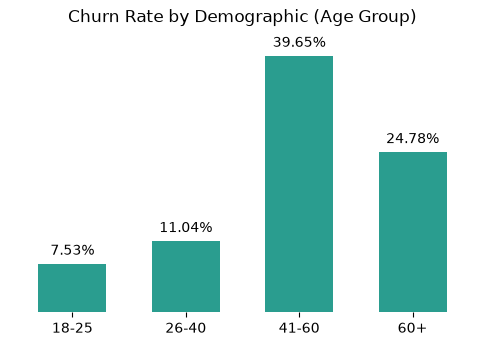

In [30]:
# Calculate numeric churn percentage for the plot heights
age_group_num = (df.groupby('AgeGroup', observed=False)['Exited'].mean() * 100).round(2)

# Plotting the demographic breakdown
fig, ax = plt.subplots(figsize=(6, 3.5))
age_group_num.plot(kind='bar', ax=ax, color='#2a9d8f', width=0.6)

# Attach the percentage labels directly onto the bars
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.2f}%',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom',
                xytext=(0, 4), textcoords='offset points')

plt.xlabel("")
plt.ylabel("")
ax.set_yticks([]) 
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

plt.title("Churn Rate by Demographic (Age Group)", fontsize=12, pad=15)
plt.xticks(rotation=0)
plt.show()

## Churn Rate by Demographic

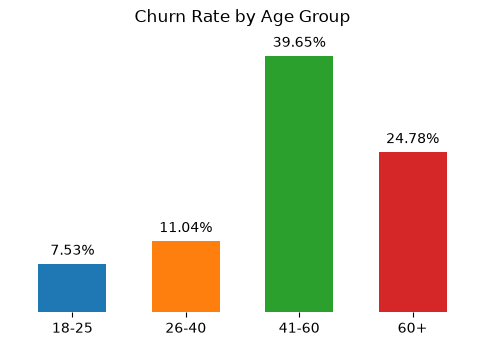

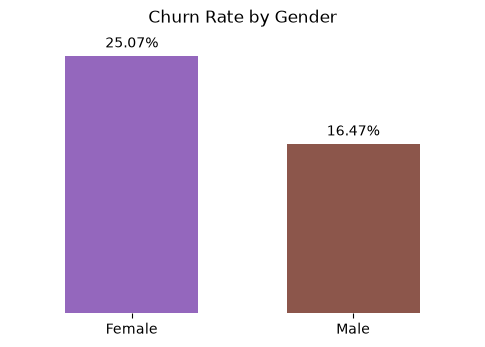

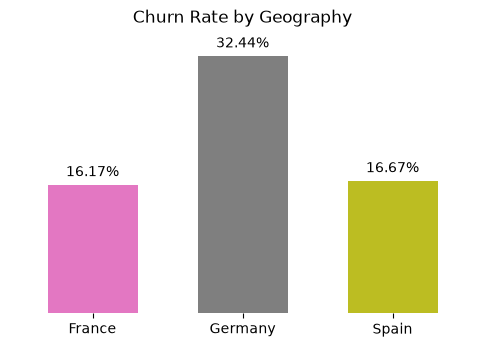

In [31]:
# Automated Churn Rate Visualization with Unique Group Colors
demographic_cols = ['AgeGroup', 'Gender', 'Geography']

# Define specific color palettes for each demographic variable's groups
color_palettes = {
    'AgeGroup': ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'], # Blue, Orange, Green, Red for age
    'Gender': ['#9467bd', '#8c564b'],                         # Purple, Brown for gender
    'Geography': ['#e377c2', '#7f7f7f', '#bcbd22']            # Pink, Gray, Olive for geography
}

for col in demographic_cols:
    if col in df.columns:
        # Calculate numeric churn percentage
        group_data = (df.groupby(col, observed=False)['Exited'].mean() * 100).round(2)

        # Select the correct color palette based on the demographic column
        current_palette = color_palettes.get(col, ['#2a9d8f']) # Default teal if not found

        # Plotting each demographic slice
        fig, ax = plt.subplots(figsize=(6, 3.5))

        # Pass the color list to the plot function
        group_data.plot(kind='bar', ax=ax, color=current_palette, width=0.6)

        # Attach percentage labels onto the bars
        for p in ax.patches:
            height = p.get_height()
            ax.annotate(f'{height:.2f}%',
                        (p.get_x() + p.get_width() / 2., height),
                        ha='center', va='bottom',
                        xytext=(0, 4), textcoords='offset points')

        plt.xlabel("")
        plt.ylabel("")
        ax.set_yticks([])
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_visible(False)
        ax.spines['bottom'].set_visible(False)

        plt.title(f"Churn Rate by {col.replace('Group', ' Group')}", fontsize=12, pad=15)
        plt.xticks(rotation=0)
        plt.show()

In [32]:
df.columns.to_list()

['CreditScore',
 'Geography',
 'Gender',
 'Age',
 'Tenure',
 'Balance',
 'NumOfProducts',
 'HasCreditCard',
 'IsActiveMember',
 'EstimatedSalary',
 'Exited',
 'Complain',
 'Satisfaction Score',
 'Card Type',
 'Point Earned',
 'AgeGroup',
 'CreditGroup',
 'BalanceGroup',
 'TenureGroup',
 'PointGroup',
 'EstimatedSalaryGroup']

## Churn Rate by Credit Score

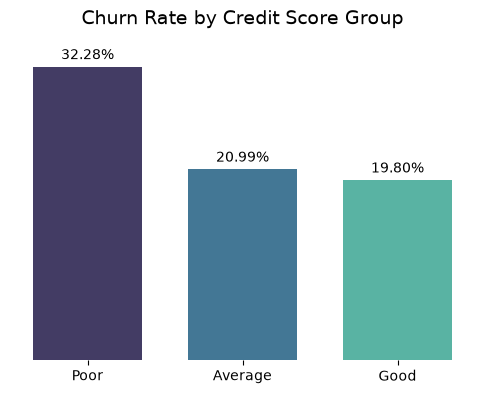

In [33]:
plt.figure(figsize=(6, 4))


ax = sns.barplot(x='CreditGroup', y='Exited', data=df, hue='CreditGroup', palette='mako', errorbar=None, dodge=False, width=0.7)


for container in ax.containers:
    ax.bar_label(container, fmt=lambda x: f'{x*100:.2f}%', padding=3)


plt.xlabel("")
plt.ylabel("")
ax.set_yticks([]) 
sns.despine(left=True, bottom=True)

plt.title("Churn Rate by Credit Score Group", fontsize=14, pad=20)
plt.show()


## Churn Rate by Card Type

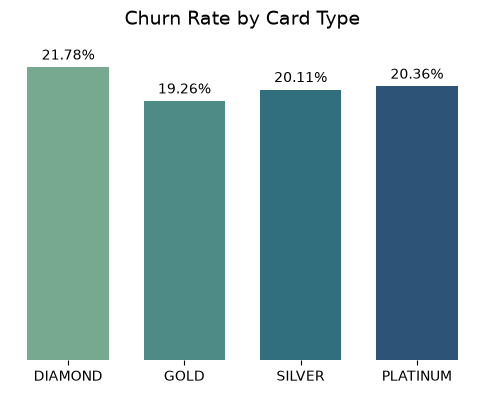

In [34]:
plt.figure(figsize=(6, 4))


ax = sns.barplot(x='Card Type', y='Exited', data=df, hue='Card Type', palette='crest', errorbar=None, dodge=False, width=0.7)


for container in ax.containers:
    ax.bar_label(container, fmt=lambda x: f'{x*100:.2f}%', padding=3)


plt.xlabel("")
plt.ylabel("")
ax.set_yticks([]) 
sns.despine(left=True, bottom=True)

plt.title("Churn Rate by Card Type", fontsize=14, pad=20)
plt.show()

## Satisfaction Score by Churn Rate

In [35]:
satisfaction_score = (df.groupby('Satisfaction Score')['Exited'].mean() * 100).round(2)
satisfaction_score.astype(str) + '%'

Satisfaction Score
1    20.03%
2     21.8%
3    19.64%
4    20.62%
5    19.81%
Name: Exited, dtype: str

## Churn Rate by Complaints

In [36]:
complaints = (df.groupby('Complain')['Exited'].mean() * 100).round(2)
complaints.astype(str) + '%'

Complain
0     0.05%
1    99.51%
Name: Exited, dtype: str

## Product Engagement vs Churn Rate

In [37]:
product = (df.groupby('NumOfProducts')['Exited'].mean() * 100).round(2)
product.astype(str) + '%'

NumOfProducts
1    27.71%
2      7.6%
3    82.71%
4    100.0%
Name: Exited, dtype: str

## Churn Rate VS Credit Card

In [38]:
credit_card = (df.groupby('HasCreditCard')['Exited'].mean() * 100).round(2)
credit_card.astype(str) + '%'

HasCreditCard
0    20.81%
1     20.2%
Name: Exited, dtype: str

## Churn Rate by Active Membership

In [39]:
active_membership = (df.groupby('IsActiveMember')['Exited'].mean() * 100).round(2)
active_membership.astype(str) + '%'

IsActiveMember
0    26.87%
1    14.27%
Name: Exited, dtype: str

## Churn Rate by Average Salary

In [40]:
average_salary = (df.groupby('EstimatedSalaryGroup')['Exited'].mean() * 100).round(2)
average_salary.astype(str) + '%'

EstimatedSalaryGroup
Low          19.93%
Medium       19.87%
High         20.23%
Very High    21.51%
Name: Exited, dtype: str

## Points Earned vs Churn Rate

In [41]:
point_earned = (df.groupby('PointGroup')['Exited'].mean()*100).round(2)
point_earned.astype(str) + '%'

PointGroup
Low       21.04%
Medium    19.86%
High       20.5%
Name: Exited, dtype: str

## Churn Risk Profile

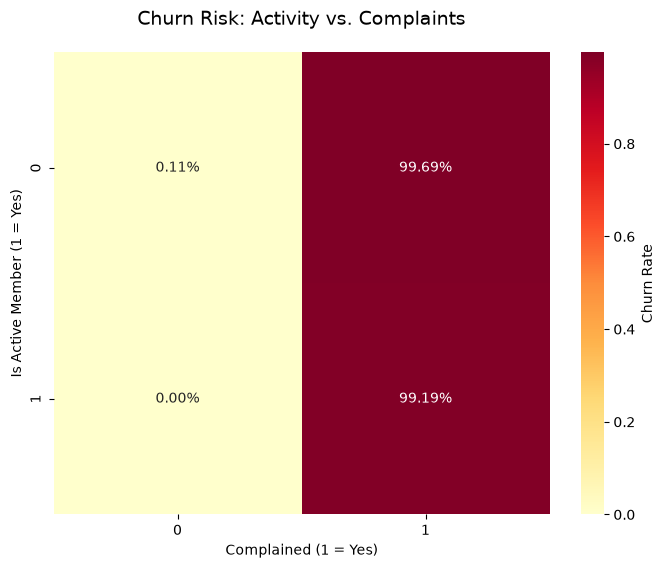

In [42]:

# Creating the pivot table based on my data
pivot_risk = df.groupby(['IsActiveMember', 'Complain'])['Exited'].mean().unstack()

plt.figure(figsize=(8, 6))
sns.heatmap(pivot_risk, annot=True, fmt=".2%", cmap='YlOrRd', cbar_kws={'label': 'Churn Rate'})

plt.title('Churn Risk: Activity vs. Complaints', fontsize=14, pad=20)
plt.xlabel('Complained (1 = Yes)')
plt.ylabel('Is Active Member (1 = Yes)')
plt.show()

#  KPI Calculations
##  Overall Churn Rate

In [43]:
churn_rate = (df['Exited'].mean() * 100).round(2)
churn_rate.astype(str)
print(f"Overall churn rate = {churn_rate}{'%'}")

Overall churn rate = 20.38%


## % of Churned Customers with Complaints

In [44]:
churn_complaint = (df[df['Exited']==1]['Complain'].mean() * 100).round(2)
churn_complaint.astype(str)
print(f"% of Churned Customers with Complaints = {churn_complaint}{'%'}")

% of Churned Customers with Complaints = 99.8%


## Average Credit Score (Churned vs Retained)

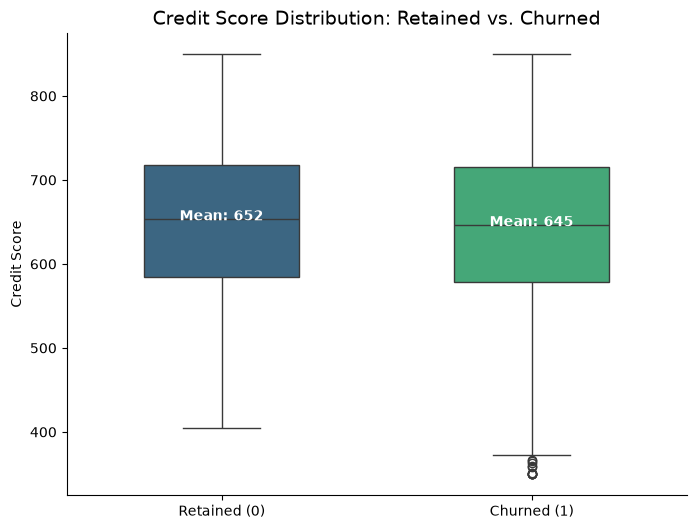

In [45]:
plt.figure(figsize=(8, 6))


ax = sns.boxplot(x='Exited', y='CreditScore', hue='Exited', data=df, palette='viridis', width=0.5, legend=False)


plt.text(0, 652, 'Mean: 652', color='white', ha='center', fontweight='bold')
plt.text(1, 645, 'Mean: 645', color='white', ha='center', fontweight='bold')

plt.title("Credit Score Distribution: Retained vs. Churned", fontsize=14)
plt.xticks([0, 1], ['Retained (0)', 'Churned (1)'])
plt.ylabel("Credit Score")
plt.xlabel("")
sns.despine()

plt.show()

## Satisfaction score Distribution by churn status

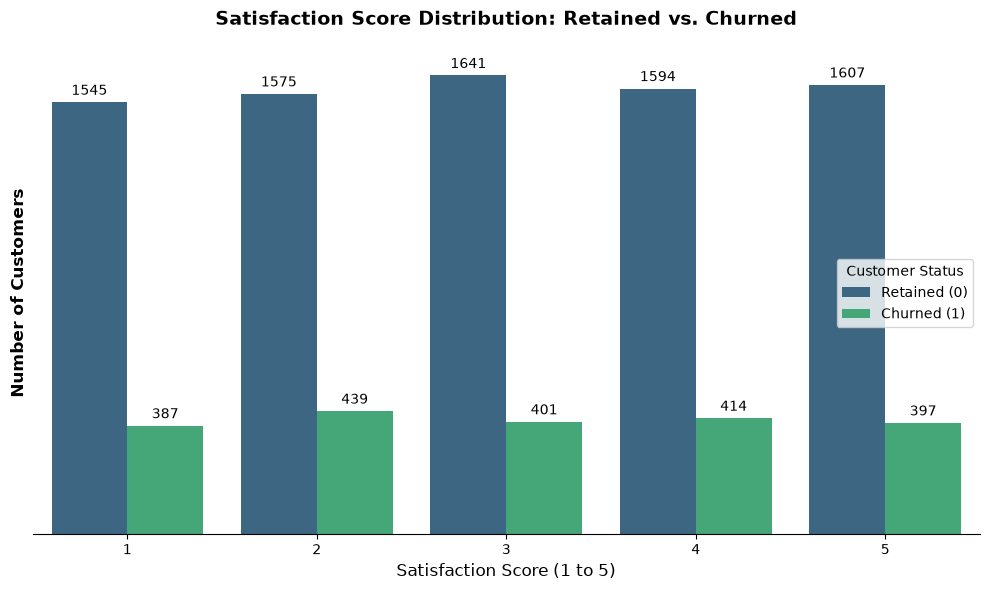

In [46]:
# Setting up the plotting canvas
plt.figure(figsize=(10, 6))

# Creating the countplot
ax = sns.countplot(data=df, x='Satisfaction Score', hue='Exited', palette='viridis')

# Add data labels directly on top of each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, fontsize=10)


ax.tick_params(left=False, labelleft=False)


ax.set_ylabel('Number of Customers', fontsize=12, fontweight='bold')


sns.despine(left=True)


plt.title('Satisfaction Score Distribution: Retained vs. Churned', pad=20, fontsize=14, fontweight='bold')
plt.xlabel('Satisfaction Score (1 to 5)', fontsize=12)
plt.legend(title='Customer Status', labels=['Retained (0)', 'Churned (1)'])
plt.tight_layout()
plt.show()

## Tenure Analysis

In [47]:
# Grouping by Tenure and calculating key metrics
tenure_analysis = df.groupby('Tenure')['Exited'].agg(
    Total_Customers='count',
    Churned_Customers='sum',
    Churn_Rate=lambda x: round(x.mean() * 100, 2)
).reset_index()

# Displaying the final data frame
print(tenure_analysis)


    Tenure  Total_Customers  Churned_Customers  Churn_Rate
0        0              413                 95       23.00
1        1             1035                232       22.42
2        2             1048                201       19.18
3        3             1009                213       21.11
4        4              989                203       20.53
5        5             1012                209       20.65
6        6              967                196       20.27
7        7             1028                177       17.22
8        8             1025                197       19.22
9        9              984                214       21.75
10      10              490                101       20.61


## Product Holding and Churn Correlation 

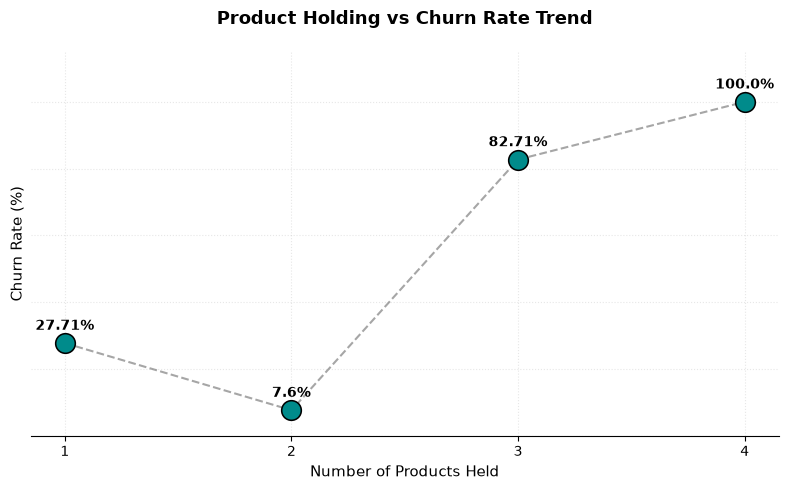

In [48]:

# Setting up the plotting canvas
plt.figure(figsize=(8, 5))

product_analysis = df.groupby('NumOfProducts')['Exited'].agg(
    Total_Customers='count',
    Churned_Customers='sum',
    Churn_Rate=lambda x: round(x.mean() * 100, 2)
).reset_index()

# Creating the scatter plot
ax = sns.scatterplot(
    data=product_analysis, 
    x='NumOfProducts', 
    y='Churn_Rate', 
    s=200, 
    color='darkcyan', 
    edgecolor='black', 
    zorder=3
)

# Connecting the scatter points with a line to visually trace the relationship
plt.plot(
    product_analysis['NumOfProducts'], 
    product_analysis['Churn_Rate'], 
    linestyle='--', 
    color='gray', 
    alpha=0.7, 
    zorder=2
)

# Step 1: Adding data labels directly above each scatter point
for idx, row in product_analysis.iterrows():
    ax.text(
        x=row['NumOfProducts'],
        y=row['Churn_Rate'] + 3,  
        s=f"{row['Churn_Rate']}%",
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold',
        color='black'
    )


ax.tick_params(left=False, labelleft=False)
ax.set_ylabel('Churn Rate (%)', fontsize=11)

# Step 3: Giving the plot breathing room at the top so the 100% label does not get clipped
plt.ylim(0, 115)

# Clearing the left boundary line for a professional finish
sns.despine(left=True)

# Polishing presentation titles and labels
plt.title('Product Holding vs Churn Rate Trend', pad=20, fontsize=13, fontweight='bold')
plt.xlabel('Number of Products Held', fontsize=11)
plt.xticks(product_analysis['NumOfProducts'])
plt.grid(True, linestyle=':', alpha=0.3, zorder=1)
plt.tight_layout()

# Saving the updated image
plt.savefig('product_holding_churn_trend_labeled.png')
plt.show()

# CHURN PREDICTION

## Prepping the Data for Scikit-Learn

In [52]:

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

In [56]:
# 1. Convert text/string columns to pandas category dtype
text_columns = ['Geography', 'Gender', 'Card Type']
for col in text_columns:
    if col in df.columns:
        df[col] = df[col].astype('category')

# 2. Re-run your feature selection and train-test split
X = df.drop(columns=['Exited', 'CustomerId', 'Surname', 'RowNumber', 'Actual_Churn', 'Predicted_Churn', 'Complain'], errors='ignore')
y = df['Exited']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Re-calculate imbalance ratio
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
spw = neg_count / pos_count

# 4. Initialize XGBoost with enable_categorical=True
xgb_model = XGBClassifier(
    scale_pos_weight=spw, 
    random_state=42, 
    eval_metric='logloss',
    enable_categorical=True  # <--- Crucial addition for category dtypes
)

# 5. Fit the model
xgb_model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [57]:
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score
from sklearn.metrics import roc_auc_score

# 1. Calculating class imbalance ratio for scale_pos_weight
neg_count = (y_train == 0).sum() # type: ignore
pos_count = (y_train == 1).sum() # type: ignore
spw = neg_count / pos_count

# 2. Initialization and trainning XGBoost with class weighting
xgb_model = XGBClassifier(
    scale_pos_weight=spw, 
    random_state=42, 
    eval_metric='logloss'
)
xgb_model.fit(X_train, y_train) # type: ignore

# 3. Letting the model decide using its default 0.5 threshold (.predict())
y_pred_test = xgb_model.predict(X_test) # type: ignore

print('--- XGBoost Test Set Evaluation (Default Threshold) ---')
print(classification_report(y_test, y_pred_test)) # type: ignore
print(f'Accuracy Score: {accuracy_score(y_test, y_pred_test):.4f}') # type: ignore

# 4. Scoring the entire dataset using default predictions
df['Churn_Probability'] = xgb_model.predict_proba(X[X_train.columns])[:, 1] # type: ignore
df['Predicted_Churn'] = xgb_model.predict(X[X_train.columns]) # type: ignore
df['Actual_Churn'] = df['Exited']

# 5. Re-exporting final scored dataset for Power BI
export_filename = 'customer_churn2_scored.csv'
df.to_csv(export_filename, index=False)
print(f'\nExported successfully to {export_filename}')



# 5. Calculating ROC-AUC score using test probabilities
test_probs = xgb_model.predict_proba(X_test)[:, 1] # type: ignore
roc_auc = roc_auc_score(y_test, test_probs) # type: ignore

print(f'ROC-AUC Score: {roc_auc:.4f}')

--- XGBoost Test Set Evaluation (Default Threshold) ---
              precision    recall  f1-score   support

           0       0.90      0.89      0.90      1592
           1       0.60      0.63      0.62       408

    accuracy                           0.84      2000
   macro avg       0.75      0.76      0.76      2000
weighted avg       0.84      0.84      0.84      2000

Accuracy Score: 0.8405

Exported successfully to customer_churn2_scored.csv
ROC-AUC Score: 0.8449


## Re-trainning the model to achieve better model evaluation Results

In [59]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, train_test_split, RandomizedSearchCV
from sklearn.metrics import classification_report, accuracy_score, precision_recall_curve, roc_auc_score
from xgboost import XGBClassifier

# 1. Advanced Feature Engineering
df['Balance_to_Salary_Ratio'] = df['Balance'] / (df['EstimatedSalary'] + 1e-5)
df['Credit_Per_Age'] = df['CreditScore'] / (df['Age'] + 1e-5)

# 2. Prepare Feature Matrix (Explicitly dropping leakage and exported columns)
drop_cols = [
    'CustomerId','Exited', 'Complain', 
    'Actual_Churn', 'Predicted_Churn', 'Churn_Probability',
    'AgeGroup', 'CreditGroup', 'BalanceGroup', 'TenureGroup', 'PointGroup', 'EstimatedSalaryGroup'
]
features_to_drop = [col for col in drop_cols if col in df.columns]

X_raw = df.drop(columns=features_to_drop)
cat_cols = X_raw.select_dtypes(include=['object', 'category']).columns.tolist()
X = pd.get_dummies(X_raw, columns=cat_cols, drop_first=True)
y = df['Exited']

# Stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Hyperparameter tuning using RandomizedSearchCV with GPU acceleration
param_distributions = {
    'n_estimators': [150, 300, 500, 700],
    'max_depth': [3, 5, 7, 9],
    'learning_rate': [0.01, 0.03, 0.05, 0.1, 0.15],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'min_child_weight': [1, 3, 5, 8],
    'scale_pos_weight': [1.0, 1.5, 2.0, 3.0, 4.0]
}

base_model = XGBClassifier(
    device='cuda',
    tree_method='hist',
    random_state=42,
    eval_metric='logloss'
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print('Running clean hyperparameter search...')
random_search = RandomizedSearchCV(
    estimator=base_model,
    param_distributions=param_distributions,
    n_iter=20,
    scoring='roc_auc',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)
random_search.fit(X_train, y_train)

print('\nBest Hyperparameters Found:')
for key, value in random_search.best_params_.items():
    print(f'{key}: {value}')

# 4. Trainning Final Model with Best Parameters
final_model = random_search.best_estimator_

# 5. Dynamic Threshold Optimization for Balanced Recall and Precision
train_probs = final_model.predict_proba(X_train)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_train, train_probs)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
optimal_threshold = thresholds[np.argmax(f1_scores)]

print(f'\nOptimized Decision Threshold: {optimal_threshold:.4f}')

# 6. Evaluating on Test Set
test_probs = final_model.predict_proba(X_test)[:, 1]
y_pred_test = (test_probs >= optimal_threshold).astype(int)

print('\n--- Clean Production XGBoost Evaluation ---')
print(classification_report(y_test, y_pred_test))
print(f'ROC-AUC Score: {roc_auc_score(y_test, test_probs):.4f}')
print(f'Accuracy Score: {accuracy_score(y_test, y_pred_test):.4f}')

# 7. Scoring Entire Dataset and Export for Power BI
df['Churn_Probability'] = final_model.predict_proba(X[X_train.columns])[:, 1]
df['Predicted_Churn'] = (df['Churn_Probability'] >= optimal_threshold).astype(int)
df['Actual_Churn'] = df['Exited']

export_filename = 'bank_churn_scored_secure.csv'
df.to_csv(export_filename, index=False)
print(f'\nExported successfully to {export_filename}')

Running clean hyperparameter search...
Fitting 5 folds for each of 20 candidates, totalling 100 fits


c:\Users\Administrator\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [11:57:46] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:55: No visible GPU is found, setting device to CPU.
  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\Administrator\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [11:57:46] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)



Best Hyperparameters Found:
subsample: 0.8
scale_pos_weight: 1.0
n_estimators: 700
min_child_weight: 8
max_depth: 5
learning_rate: 0.01
colsample_bytree: 0.6

Optimized Decision Threshold: 0.2909

--- Clean Production XGBoost Evaluation ---
              precision    recall  f1-score   support

           0       0.92      0.88      0.90      1592
           1       0.59      0.69      0.64       408

    accuracy                           0.84      2000
   macro avg       0.75      0.78      0.77      2000
weighted avg       0.85      0.84      0.84      2000

ROC-AUC Score: 0.8751
Accuracy Score: 0.8400

Exported successfully to bank_churn_scored_secure.csv


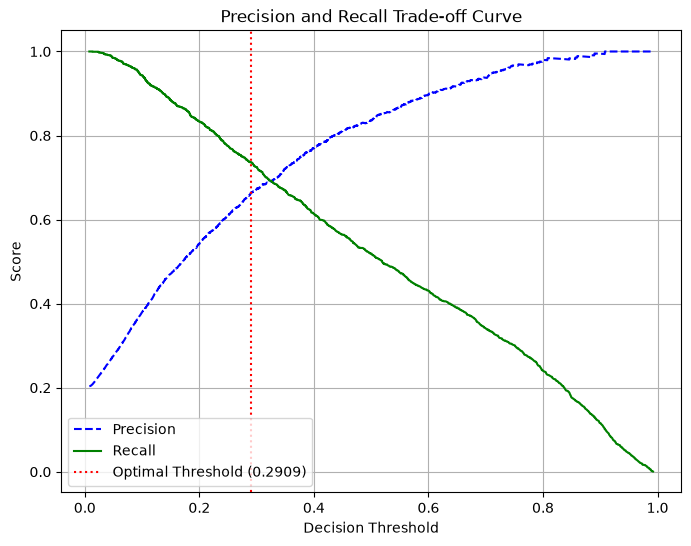

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import precision_recall_curve

# 1. Recalculating probabilities and precision-recall values from the trained model
train_probs = final_model.predict_proba(X_train)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_train, train_probs)

# 2. Computing the optimal threshold
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
optimal_threshold = thresholds[np.argmax(f1_scores)]

# 3. Plotting the Precision-Recall Trade-off Curve
plt.figure(figsize=(8, 6))
plt.plot(
    thresholds, precisions[:-1], color='blue', linestyle='--', label='Precision'
)
plt.plot(
    thresholds, recalls[:-1], color='green', linestyle='-', label='Recall'
)
plt.axvline(
    x=optimal_threshold,
    color='red',
    linestyle=':',
    label=f'Optimal Threshold ({optimal_threshold:.4f})',
)

plt.xlabel('Decision Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall Trade-off Curve')
plt.legend(loc='best')
plt.grid(True)
plt.show()

In [ ]:
# 1. CustomerId was missing in the final dataset so I had to include it
df_raw = pd.read_csv('bank_churn_raw.csv')

if 'CustomerId' not in df.columns:
    df['CustomerId'] = df_raw['CustomerId']

# 2. Attaching prediction scores
df['Churn_Probability'] = final_model.predict_proba(X[X_train.columns])[:, 1]
df['Predicted_Churn'] = (df['Churn_Probability'] >= optimal_threshold).astype(int)
df['Actual_Churn'] = df['Exited']

# 3. Exporting to the exact filename Power BI reads
export_filename = 'bank_churn_scored_secure.csv'
df.to_csv(export_filename, index=False)

print(f'Done! CustomerId is present: {"CustomerId" in df.columns}')
print(f'File saved to: {export_filename}')

Done! CustomerId is present: True
File saved to: bank_churn_scored_secure.csv


In [ ]:
#Fixing the duplicate column error(Actual_churn and Exited are the same
# 1. Removing duplicate column names if any exist
df = df.loc[:, ~df.columns.duplicated()].copy()

# 2. Ensuring Actual_Churn matches Exited cleanly
if 'Exited' in df.columns:
    df['Actual_Churn'] = df['Exited']

# 3. Exporting to CSV
export_filename = 'bank_churn_scored_secure.csv'
df.to_csv(export_filename, index=False)
print('Exported cleanly without duplicate column names!')

Exported cleanly without duplicate column names!


In [ ]:
print(df.columns.to_list())

['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCreditCard', 'IsActiveMember', 'EstimatedSalary', 'Exited', 'Complain', 'Satisfaction Score', 'Card Type', 'Point Earned', 'AgeGroup', 'CreditGroup', 'BalanceGroup', 'TenureGroup', 'PointGroup', 'EstimatedSalaryGroup', 'Balance_to_Salary_Ratio', 'Credit_Per_Age', 'Churn_Probability', 'Predicted_Churn', 'Actual_Churn', 'CustomerId']
